In [1]:
import pandas as pd
import numpy as np
import os
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

In [2]:
ROOT = Path.cwd().parent

DATA_DIR = (ROOT / "edaic-woz" / "data") if (ROOT / "edaic-woz" / "data").exists() else (ROOT / "data")
LABEL_DIR = (ROOT / "edaic-woz" / "labels") if (ROOT / "edaic-woz" / "labels").exists() else (ROOT / "labels")

print(ROOT)
print(DATA_DIR)
print(LABEL_DIR)

E:\EDAIC-WOZ
E:\EDAIC-WOZ\data
E:\EDAIC-WOZ\labels


In [3]:
train_labels = pd.read_csv(LABEL_DIR / "train_split.csv")
dev_labels   = pd.read_csv(LABEL_DIR / "dev_split.csv")
test_labels  = pd.read_csv(LABEL_DIR / "test_split.csv")

print(train_labels.shape)
print(dev_labels.shape)
print(test_labels.shape)

(163, 6)
(56, 6)
(56, 6)


In [4]:
def get_feature_path(pid, feature_type="eGeMAPS"):
    if feature_type == "eGeMAPS":
        return (
            DATA_DIR
            / f"{pid}_P"
            / "features"
            / f"{pid}_BoAW_openSMILE_2.3.0_eGeMAPS.csv"
        )

    if feature_type == "MFCC":
        return (
            DATA_DIR
            / f"{pid}_P"
            / "features"
            / f"{pid}_BoAW_openSMILE_2.3.0_MFCC.csv"
        )

In [5]:
pid = 300

feature_file = get_feature_path(pid, "eGeMAPS")

df = pd.read_csv(feature_file)

print("Shape:", df.shape)
display(df.head())

Shape: (6484, 102)


,'unknown',0.0,1.4149733999999998,0.0.1,0.0.2,0.0.3,0.0.4,0.0.5,0.0.6,0.0.7,...,0.0.67,0.0.68,0.0.69,0.0.70,0.0.71,0.0.72,0.0.73,1.4313638000000002,0.0.74,0.0.75
0,'unknown',0.1,1.414973,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.462398,0.0,0.0
1,'unknown',0.2,1.414973,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.518514,0.0,0.0
2,'unknown',0.3,1.414973,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.544068,0.0,0.0
3,'unknown',0.4,1.414973,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.544068,0.0,0.0
4,'unknown',0.5,1.414973,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.544068,0.0,0.0


In [6]:
df.columns.tolist()
df.info

<bound method DataFrame.info of       'unknown'    0.0  1.4149733999999998     0.0.1  0.0.2  0.0.3  0.0.4  \
0     'unknown'    0.1            1.414973  0.000000    0.0    0.0    0.0   
1     'unknown'    0.2            1.414973  0.000000    0.0    0.0    0.0   
2     'unknown'    0.3            1.414973  0.000000    0.0    0.0    0.0   
3     'unknown'    0.4            1.414973  0.000000    0.0    0.0    0.0   
4     'unknown'    0.5            1.414973  0.000000    0.0    0.0    0.0   
...         ...    ...                 ...       ...    ...    ...    ...   
6479  'unknown'  648.0            0.000000  1.176091    0.0    0.0    0.0   
6480  'unknown'  648.1            0.000000  1.176091    0.0    0.0    0.0   
6481  'unknown'  648.2            0.000000  1.176091    0.0    0.0    0.0   
6482  'unknown'  648.3            0.000000  1.176091    0.0    0.0    0.0   
6483  'unknown'  648.4            0.000000  1.176091    0.0    0.0    0.0   

      0.0.5    0.0.6    0.0.7  ...  0.0.67 

In [7]:
numeric_df = df.select_dtypes(include=np.number)

print(numeric_df.shape)

(6484, 101)


In [8]:
participant_features = numeric_df.mean()

print(participant_features.shape)

(101,)


In [9]:
def extract_egemaps(pid):

    feature_file = get_feature_path(pid, "eGeMAPS")

    df = pd.read_csv(
        feature_file,
        header=None
    )

    # Remove metadata columns only
    acoustic_df = df.iloc[:, 2:]

    return acoustic_df.mean()

In [10]:
features = extract_egemaps(300)

print(features.shape)
print(features.head())

(100,)
2    0.339651
3    0.309486
4    0.098401
5    0.000000
6    0.030742
dtype: float64


In [11]:
rows = []

for _, row in train_labels.iterrows():

    pid = row["Participant_ID"]

    try:
        features = extract_egemaps(pid)

        feature_dict = features.to_dict()

        feature_dict["Participant_ID"] = pid
        feature_dict["PHQ_Binary"] = row["PHQ_Binary"]
        feature_dict["PHQ_Score"] = row["PHQ_Score"]

        rows.append(feature_dict)

    except Exception as e:
        print(pid, e)

In [12]:
dataset = pd.DataFrame(rows)

print(dataset.shape)

dataset.head()

(163, 103)


,2,3,4,5,6,7,8,9,10,11,...,95,96,97,98,99,100,101,Participant_ID,PHQ_Binary,PHQ_Score
0,0.431654,0.008801,0.070662,0.003179,0.027842,0.008674,0.063036,0.172168,0.007635,1.226420,...,0.004769,0.036439,0.000000,0.000000,1.301627,0.625192,0.000000,302,0,4
1,0.688838,1.028125,0.041777,0.000000,0.434868,0.151256,0.025126,0.557120,0.003796,0.795972,...,0.010686,0.020555,0.000000,0.000000,1.240207,0.662137,0.003732,303,0,0
2,0.594773,0.658804,0.043229,0.000000,0.336465,0.103073,0.010107,0.303097,0.005749,0.999255,...,0.010145,0.012753,0.000000,0.000000,1.275509,0.773041,0.000000,304,0,6
3,0.019933,0.619588,0.009948,0.003398,0.023531,0.081506,0.002844,0.306944,0.000000,0.032020,...,0.000000,0.022808,0.003079,0.200938,0.051655,0.055726,0.000000,305,0,7
4,0.025780,1.408446,0.044388,0.000000,0.349453,0.106781,0.002917,0.133493,0.000997,0.023163,...,0.000972,0.000000,0.009310,0.237264,0.035164,0.109878,0.000000,307,0,4


In [13]:
dataset.info()

dataset.isnull().sum().sort_values(
    ascending=False
).head(20)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 163 entries, 0 to 162
Columns: 103 entries, 2 to PHQ_Score
dtypes: float64(100), int64(3)
memory usage: 131.3 KB


2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
dtype: int64

In [14]:
missing = dataset.isnull().sum()

print("Total missing values:", missing.sum())

missing[missing > 0].sort_values(ascending=False)

Total missing values: 0


Series([], dtype: int64)

In [15]:
dataset["PHQ_Binary"].value_counts()

PHQ_Binary
0    126
1     37
Name: count, dtype: int64

In [16]:
dataset["PHQ_Binary"].value_counts(normalize=True)

PHQ_Binary
0    0.773006
1    0.226994
Name: proportion, dtype: float64

In [17]:
X = dataset.drop(
    columns=[
        "Participant_ID",
        "PHQ_Binary",
        "PHQ_Score"
    ]
)

y = dataset["PHQ_Binary"]

print(X.shape)
print(y.shape)

(163, 100)
(163,)


In [18]:
constant_cols = [
    col for col in X.columns
    if X[col].nunique() <= 1
]

print("Constant columns:", len(constant_cols))

Constant columns: 0


In [19]:
print(X.shape)

(163, 100)


In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [21]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced"
)

scores = cross_val_score(
    model,
    X_scaled,
    y,
    cv=cv,
    scoring="f1"
)

print("Fold scores:", scores)
print("Mean F1:", scores.mean())
print("Std:", scores.std())

Fold scores: [0.22222222 0.3        0.31578947 0.14285714 0.125     ]
Mean F1: 0.2211737677527151
Std: 0.07816609660815832


In [22]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

scores = cross_val_score(
    rf,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print("Mean F1:", scores.mean())

Mean F1: 0.0


In [23]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ("selector", SelectKBest(f_classif, k=5)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000
    ))
])

scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print(scores)
print(scores.mean())

[0.33333333 0.15384615 0.46153846 0.42105263 0.43478261]
0.3609106377985096


In [24]:
from sklearn.pipeline import Pipeline

results = {}

for k in [5,10,15,20,30,50]:

    pipeline = Pipeline([
        ("selector", SelectKBest(f_classif, k=k)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000
        ))
    ])

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="f1"
    )

    results[k] = scores.mean()

print(results)

{5: np.float64(0.3609106377985096), 10: np.float64(0.3495652173913043), 15: np.float64(0.3467499252665493), 20: np.float64(0.2652701660374294), 30: np.float64(0.2111317509459924), 50: np.float64(0.21311145510835913)}


In [25]:
selector = SelectKBest(
    score_func=f_classif,
    k=5
)

selector.fit(X, y)

selected_features = X.columns[selector.get_support()]

for feature in selected_features:
    print(feature)

12
26
35
57
60


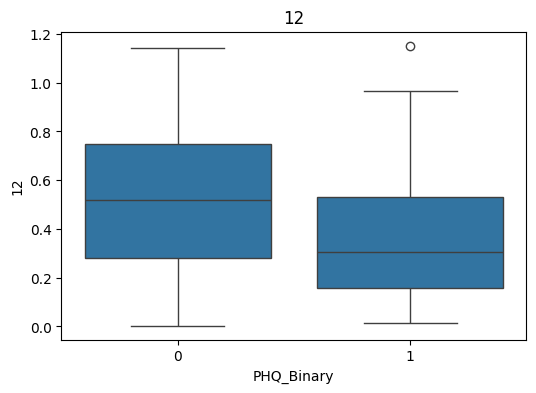

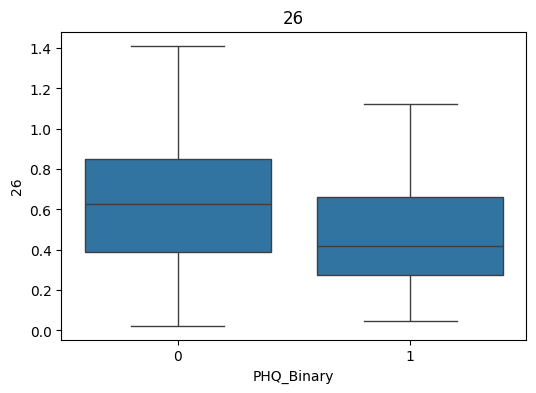

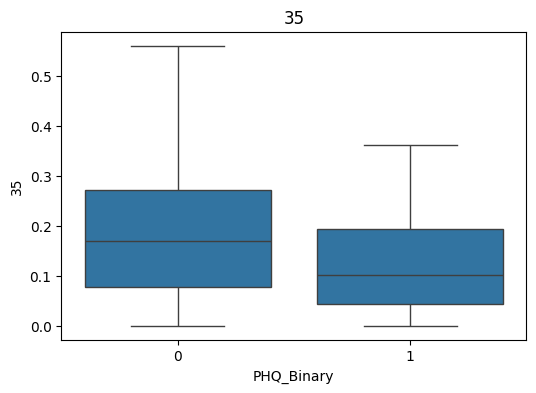

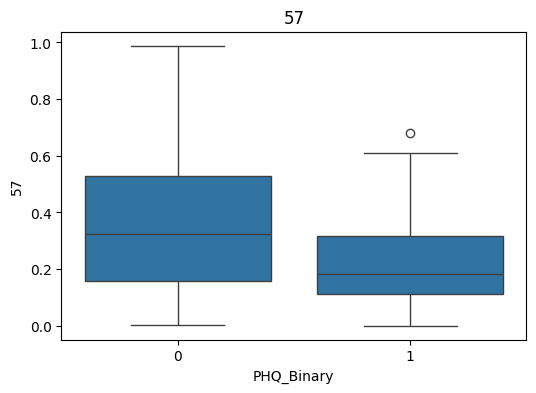

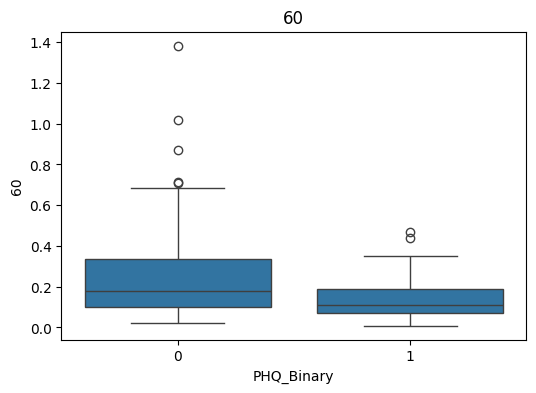

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

for feature in selected_features:

    plt.figure(figsize=(6,4))

    sns.boxplot(
        x=dataset["PHQ_Binary"],
        y=dataset[feature]
    )

    plt.title(feature)

    plt.show()

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="l1",
        solver="liblinear",
        class_weight="balanced",
        max_iter=2000
    ))
])

scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print(scores.mean())

0.31126492702344094


In [28]:
neg = (y == 0).sum()
pos = (y == 1).sum()

scale_pos_weight = neg / pos

print(scale_pos_weight)

3.4054054054054053


In [29]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss"
)

scores = cross_val_score(
    xgb,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print(scores)
print(scores.mean())
print(scores.std())

[0.         0.         0.28571429 0.2        0.        ]
0.09714285714285714
0.12202375145178641


In [30]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif

pipeline = Pipeline([
    ("selector", SelectKBest(f_classif, k=5)),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric="logloss"
    ))
])

scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print(scores)
print(scores.mean())

[0.18181818 0.         0.33333333 0.26666667 0.15384615]
0.18713286713286711


In [31]:
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import cross_val_score

pipeline = Pipeline([
    ("selector", SelectKBest(f_classif, k=5)),
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        class_weight="balanced",
        max_iter=5000
    ))
])

scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print(scores.mean())

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

preds = cross_val_predict(
    pipeline,
    X,
    y,
    cv=cv
)

print(classification_report(y, preds))

0.36564835164835163
              precision    recall  f1-score   support

           0       0.82      0.60      0.69       126
           1       0.29      0.57      0.39        37

    accuracy                           0.59       163
   macro avg       0.56      0.58      0.54       163
weighted avg       0.70      0.59      0.62       163



In [61]:
def extract_egemaps(pid):

    feature_file = get_feature_path(pid, "eGeMAPS")

    df = pd.read_csv(
    feature_file,
    sep=";",
    header=None
    )

    acoustic_df = df.iloc[:, 2:]

    acoustic_df = acoustic_df.apply(
    pd.to_numeric,
    errors="coerce"
    )

    return acoustic_df.mean()

In [63]:
rows = []

for _, row in test_labels.iterrows():

    pid = row["Participant_ID"]

    try:
        features = extract_egemaps(pid)

        feature_dict = features.to_dict()

        feature_dict["Participant_ID"] = pid
        feature_dict["PHQ_Binary"] = row["PHQ_Binary"]
        feature_dict["PHQ_Score"] = row["PHQ_Score"]

        rows.append(feature_dict)

    except Exception as e:
        print(f"Failed PID {pid}: {e}")

test_dataset = pd.DataFrame(rows)

print(test_dataset.shape)
test_dataset.head()

(56, 103)


,2,3,4,5,6,7,8,9,10,11,...,95,96,97,98,99,100,101,Participant_ID,PHQ_Binary,PHQ_Score
0,1.100306,0.235915,0.007697,0.000000,0.012885,0.024129,0.005387,0.142270,0.003562,1.030085,...,0.005343,0.002867,0.0,0.0,1.574370,0.474432,0.000000,600,0,5
1,1.012279,0.496405,0.009589,0.004040,0.173266,0.016053,0.019812,0.376848,0.013231,0.894622,...,0.028436,0.192408,0.0,0.0,1.331446,0.350649,0.007097,602,1,13
2,0.793718,0.129018,0.001940,0.003936,0.008853,0.018011,0.042857,0.109466,0.050742,1.100760,...,0.016357,0.067351,0.0,0.0,1.280202,0.235489,0.008962,604,1,12
3,0.846611,0.040731,0.000000,0.000000,0.055782,0.007442,0.087977,0.167488,0.007042,1.060366,...,0.019478,0.202438,0.0,0.0,1.191645,0.239051,0.000000,605,0,2
4,1.066875,0.049133,0.008251,0.000173,0.050956,0.004603,0.004660,0.188264,0.013628,1.079386,...,0.002301,0.100907,0.0,0.0,1.508905,0.045202,0.008251,606,0,5


In [64]:
X_test = test_dataset.drop(
    columns=[
        "Participant_ID",
        "PHQ_Binary",
        "PHQ_Score"
    ]
)

y_test = test_dataset["PHQ_Binary"]

print(X_test.shape)
print(y_test.shape)

(56, 100)
(56,)


In [66]:
print(X.shape)
print(X_test.shape)

print(
    X.columns.equals(
        X_test.columns
    )
)

(163, 100)
(56, 100)
True


In [76]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

model = Pipeline([
    ("selector", SelectKBest(
        score_func=f_classif,
        k=10
    )),
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

model.fit(X, y)

Pipeline(steps=[('selector', SelectKBest()), ('scaler', StandardScaler()),
                ('svm',
                 LinearSVC(class_weight='balanced', max_iter=5000,
                           random_state=42))])

In [77]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

y_pred = model.predict(X_test)

print("F1:", f1_score(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

F1: 0.4444444444444444

Classification Report
              precision    recall  f1-score   support

           0       0.74      0.36      0.48        39
           1       0.32      0.71      0.44        17

    accuracy                           0.46        56
   macro avg       0.53      0.53      0.46        56
weighted avg       0.61      0.46      0.47        56


Confusion Matrix
[[14 25]
 [ 5 12]]


In [78]:
selector = model.named_steps["selector"]

selected_features = X.columns[
    selector.get_support()
]

print(selected_features.tolist())

[8, 12, 23, 26, 35, 49, 50, 57, 60, 66]


In [79]:
for k in [5, 10, 15, 20, 30, 50, 100]:

    pipeline = Pipeline([
        ("selector", SelectKBest(f_classif, k=k)),
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        ))
    ])

    pipeline.fit(X, y)

    preds = pipeline.predict(X_test)

    f1 = f1_score(y_test, preds)

    print(f"k={k:<3} F1={f1:.4f}")

k=5   F1=0.4483
k=10  F1=0.4444
k=15  F1=0.4364
k=20  F1=0.4444
k=30  F1=0.4643
k=50  F1=0.4231
k=100 F1=0.4878
